# Exercise 1

Create a model using K-Nearest Neigbors to perform classification using the personality dataset.

0 -'introvert'

1 - 'extrovert'

## A. Import libraries

In [26]:
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, ConfusionMatrixDisplay

from google.colab import drive
drive.mount('/content/drive')
df = pd.read_csv('/content/drive/MyDrive/Exercise1/personality_dataset.csv')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [27]:
import os
file_path = '/content/drive/MyDrive/Exercise1/personality_dataset.csv'
if os.path.exists(file_path):
    print(f"The file '{file_path}' exists.")
    df = pd.read_csv(file_path)
else:
    print(f"The file '{file_path}' does NOT exist. Please verify the path.")

The file '/content/drive/MyDrive/Exercise1/personality_dataset.csv' exists.


## B. Load and understand the dataset

Display the first 5 rows of the dataset using `.head()`

In [28]:
print(df.head())

   Time_spent_Alone Stage_fear  Social_event_attendance  Going_outside  \
0                 3        Yes                        6              7   
1                 2         No                        8              6   
2                 1         No                        9              4   
3                 8         No                        0              0   
4                 5        Yes                        3              0   

  Drained_after_socializing  Friends_circle_size  Post_frequency Personality  
0                        No                   14               5   Extrovert  
1                        No                    7               8   Extrovert  
2                        No                    9               3   Extrovert  
3                       Yes                    9               3   Introvert  
4                        No                    2               6   Introvert  


Display the summary of all the features of the dataset using `.info()`

In [29]:
print(df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 8 columns):
 #   Column                     Non-Null Count  Dtype 
---  ------                     --------------  ----- 
 0   Time_spent_Alone           5000 non-null   int64 
 1   Stage_fear                 5000 non-null   object
 2   Social_event_attendance    5000 non-null   int64 
 3   Going_outside              5000 non-null   int64 
 4   Drained_after_socializing  5000 non-null   object
 5   Friends_circle_size        5000 non-null   int64 
 6   Post_frequency             5000 non-null   int64 
 7   Personality                5000 non-null   object
dtypes: int64(5), object(3)
memory usage: 312.6+ KB
None


Display the total number of samples from each label using `.value_counts()`

In [30]:
print(df['Personality'].value_counts())

Personality
Introvert    2502
Extrovert    2498
Name: count, dtype: int64


Use a histogram to display the number of followers for each samples
 - The x axis should be the number of followers/friends
 - The y axis should be the number of samples in the dataset

In [31]:
print(df['Personality'].value_counts())

Personality
Introvert    2502
Extrovert    2498
Name: count, dtype: int64


Remove the name column using `drop()` method

In [32]:
df = df.drop(columns=['name'], errors='ignore')
print(df.head())

   Time_spent_Alone Stage_fear  Social_event_attendance  Going_outside  \
0                 3        Yes                        6              7   
1                 2         No                        8              6   
2                 1         No                        9              4   
3                 8         No                        0              0   
4                 5        Yes                        3              0   

  Drained_after_socializing  Friends_circle_size  Post_frequency Personality  
0                        No                   14               5   Extrovert  
1                        No                    7               8   Extrovert  
2                        No                    9               3   Extrovert  
3                       Yes                    9               3   Introvert  
4                        No                    2               6   Introvert  


## C. Split the dataset into training and test set

Convert the features into an numpy array using `.values()` and store it in a variable "X"

In [33]:
X = df.drop('Personality', axis=1).values
print(X)

[[3 'Yes' 6 ... 'No' 14 5]
 [2 'No' 8 ... 'No' 7 8]
 [1 'No' 9 ... 'No' 9 3]
 ...
 [2 'No' 7 ... 'No' 11 3]
 [2 'Yes' 9 ... 'No' 15 7]
 [4 'Yes' 6 ... 'No' 12 3]]


Convert the labels into an numpy array using `.values()` and store it in a variable "y"

In [34]:
y = df['Personality'].values
print(y)

['Extrovert' 'Extrovert' 'Extrovert' ... 'Extrovert' 'Extrovert'
 'Extrovert']


Use `train_test_split()` to split the data.

- Declare a variable `X_train` that will hold the training data
- Declare a variable `X_test` that will hold the test data
- Declare a variable `y_train` that will hold the label of the training data
- Declare a variable `y_test` that will hold the label of the test data


In [35]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

Display the dimensions of each variables using `.shape()`

In [36]:
print('X_train:', X_train.shape)
print('X_test:', X_test.shape)
print('y_train:', y_train.shape)
print('y_test:', y_test.shape)

X_train: (4000, 7)
X_test: (1000, 7)
y_train: (4000,)
y_test: (1000,)


## D. Create the model

In [37]:
from sklearn.preprocessing import LabelEncoder

le = LabelEncoder()

df['Stage_fear'] = le.fit_transform(df['Stage_fear'])
df['Drained_after_socializing'] = le.fit_transform(df['Drained_after_socializing'])

df['Personality'] = le.fit_transform(df['Personality'])

X = df.drop('Personality', axis=1).values
y = df['Personality'].values

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

Use KNN as a classifier by using `KNeighborsClassifier()`

In [38]:
knn = KNeighborsClassifier(n_neighbors=3)

Train the model using the `.fit()`

In [39]:
knn.fit(X_train, y_train)

KNeighborsClassifier(n_neighbors=3)

Test the model using the `.predict()`

In [40]:
y_pred = knn.predict(X_test)
print(y_pred)

[0 0 1 0 0 0 0 1 0 1 1 1 1 1 0 0 1 1 0 0 0 0 0 0 1 1 1 0 0 0 1 1 0 0 1 1 1
 0 0 0 0 1 1 0 0 0 1 0 0 0 1 0 1 0 1 0 1 0 1 0 0 1 0 1 1 0 1 1 0 1 1 0 1 0
 1 1 0 0 1 0 1 0 0 1 1 1 0 0 0 0 0 0 1 1 0 0 0 0 0 0 0 0 0 1 0 0 0 1 0 1 1
 1 1 1 0 0 1 0 0 0 1 1 0 1 1 0 0 0 1 0 1 1 0 1 1 1 0 0 1 1 1 1 1 0 1 1 0 0
 1 0 0 1 0 1 0 1 0 1 1 0 0 0 0 0 0 0 0 0 1 1 0 0 0 1 0 1 1 1 0 1 1 1 0 1 1
 0 0 0 1 0 0 0 1 1 1 1 0 1 1 0 0 0 1 1 0 1 0 0 1 1 1 1 0 1 0 1 0 0 1 1 0 1
 0 1 0 1 0 0 1 1 0 0 1 1 1 1 0 1 1 0 1 0 1 0 1 0 0 0 1 0 1 0 0 1 1 1 0 1 0
 0 1 0 0 0 0 0 1 0 0 1 1 0 0 0 1 1 1 0 1 1 0 1 1 1 0 0 1 1 1 1 1 1 1 0 1 0
 0 1 1 0 0 0 1 0 1 1 0 0 0 0 1 1 1 1 1 1 0 1 0 1 0 0 0 0 1 1 1 0 0 0 0 0 1
 1 1 1 0 1 0 0 0 1 0 0 1 0 1 1 0 1 0 0 0 1 1 1 0 0 1 1 1 0 0 0 0 0 1 0 0 0
 0 1 1 1 0 0 1 0 1 0 0 1 0 1 0 0 0 0 0 0 0 1 0 0 1 1 1 1 1 1 1 1 1 1 1 1 0
 1 1 1 1 0 1 1 1 0 1 0 0 1 0 1 1 1 1 0 0 1 1 0 0 1 0 0 1 1 0 1 1 1 0 0 0 1
 0 0 0 0 1 1 1 0 0 1 0 1 1 0 1 1 1 1 0 1 0 0 0 0 0 0 0 1 0 1 1 1 1 1 0 0 1
 1 0 1 0 0 1 1 1 1 1 0 1 

## E. Evaluate the model

Create a confusion matrix

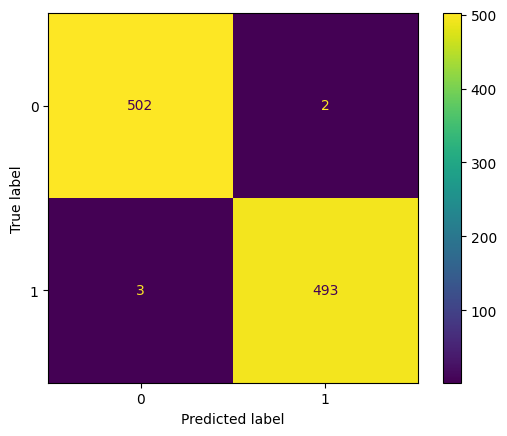

In [41]:
cm = confusion_matrix(y_test, y_pred)

disp = ConfusionMatrixDisplay(confusion_matrix=cm)
disp.plot()
plt.show()

Display the accuracy

In [42]:
accuracy = accuracy_score(y_test, y_pred)
print('Accuracy:', accuracy)

Accuracy: 0.995


Display the precision

In [43]:
precision = precision_score(y_test, y_pred)
print('Precision:', precision)

Precision: 0.9959595959595959


Display the recall

In [44]:
recall = recall_score(y_test, y_pred)
print('Recall:', recall)

Recall: 0.9939516129032258


Display the f1-score

In [45]:
f1 = f1_score(y_test, y_pred)
print('F1-score:', f1)

F1-score: 0.9949545913218971


## F. Predict your own personality

Enter your own features and use the model to generate a prediction using `.predict()`

In [46]:
my_features = [[5, 0, 6, 5, 0, 8, 4]]

prediction = knn.predict(my_features)

print('Prediction:', prediction)

if prediction[0] == 0:
    print('Prediction: Extrovert')
else:
    print('Prediction: Introvert')

Prediction: [0]
Prediction: Extrovert
